# Predicting ATP match winners with Elo

Each player gets an **Elo rating** that goes up when they win and down when
they lose, by more when the result is a surprise. Before every match, the
two ratings give a win probability, and that is the prediction.

The ratings are built from **every ATP tour-level match** in the
[tennis-data.co.uk](http://www.tennis-data.co.uk/) files in `atp_data/`, one
file per year. (The Match Charting Project only has a sample of matches,
which would leave big gaps in players' histories.)

The notebook:

1. Loads and cleans the matches.
2. Builds the Elo step by step: a basic version, then surface-specific
   ratings, margin of victory and a best-of-5 adjustment.
3. Tests it year by year from 2008: each year's settings are tuned on the
   3 years before it, and each step is kept only if it helps.
4. Compares against two baselines: picking the higher-ranked player, and the
   bookmakers' odds.

Every prediction uses only matches played before it.

## 1. Load the matches

In [1]:
import glob
import math
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message=".*xlrd.*")
warnings.filterwarnings("ignore", message="Unknown extension")
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

files = sorted(glob.glob(os.path.join("atp_data", "*.xls*")))
raw = pd.concat([pd.read_excel(f) for f in files], ignore_index=True)
print(f"{len(files)} files ({os.path.basename(files[0])} to "
      f"{os.path.basename(files[-1])}), {len(raw):,} matches")
raw.head(3)

27 files (2000.xls to 2026.xlsx), 71,707 matches


,ATP,Location,Tournament,Date,Series,Court,Surface,Round,Best of,Winner,Loser,WRank,LRank,W1,L1,...,PSL,WPts,LPts,UBW,UBL,LBW,LBL,SJW,SJL,MaxW,MaxL,AvgW,AvgL,BFEW,BFEL
0,1,Adelaide,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3.0,Dosedel S.,Ljubicic I.,63,77,6.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Adelaide,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3.0,Enqvist T.,Clement A.,5,56,6.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,Adelaide,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3.0,Escude N.,Baccanello P.,40,655,6.0,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Cleaning:

- **Order**: older files only give each tournament's start date, so matches
  are ordered by date, then tournament, then round (first round before the
  final).
- **Matches not played** (walkovers, and the odd "Awarded" or "Sched"
  entry) are dropped.
- **Retirements** (and the rare disqualification) are kept and flagged;
  whether they should move the ratings is tuned later.
- **Player names** spelled more than one way are merged.
- **Rankings** that are missing or "NR" become missing values.
- **Games won** by each player are added up from the set scores, for the
  margin of victory.

In [2]:
ROUNDS = {"1st Round": 1, "2nd Round": 2, "3rd Round": 3, "4th Round": 4,
          "Round Robin": 5, "Quarterfinals": 6, "Semifinals": 7,
          "The Final": 8}

NOT_PLAYED = ["Walkover", "Awarded", "Sched"]
matches = raw[~raw["Comment"].isin(NOT_PLAYED)].copy()
# Some players' names are spelled more than one way ("Carreno-Busta P." and
# "Carreno Busta P."): map every spelling to the player's most common one.
names = pd.concat([matches["Winner"], matches["Loser"]]).str.strip()
key = names.str.lower().str.replace(r"[^a-z]", "", regex=True)
canonical = (pd.DataFrame({"name": names, "key": key})
             .groupby("key")["name"].agg(lambda n: n.value_counts().index[0]))
for side in ("Winner", "Loser"):
    spelled = matches[side].str.strip()
    matches[side] = spelled.str.lower().str.replace(
        r"[^a-z]", "", regex=True).map(canonical)
print(f"{names.nunique() - len(canonical)} alternative name spellings merged")
matches["Year"] = matches["Date"].dt.year
matches["round_order"] = matches["Round"].map(ROUNDS).fillna(0)
matches["retired"] = matches["Comment"] != "Completed"
for side in ("W", "L"):
    matches[f"{side}Rank"] = pd.to_numeric(matches[f"{side}Rank"],
                                           errors="coerce")
    matches[f"{side}games"] = matches[[f"{side}{k}" for k in range(1, 6)]
                                      ].apply(pd.to_numeric,
                                              errors="coerce").sum(axis=1)
matches = (matches.reset_index(names="row")
                  .sort_values(["Date", "ATP", "round_order", "row"])
                  .reset_index(drop=True))
print(f"{len(matches):,} matches after dropping "
      f"{len(raw) - len(matches)} not played; "
      f"{matches['retired'].sum()} retirements or disqualifications")
print(matches.groupby("Year").size().to_string())

39 alternative name spellings merged


71,311 matches after dropping 396 not played; 2204 retirements or disqualifications
Year
2000    2949
2001    3051
2002    2799
2003    2800
2004    2870
2005    2899
2006    2897
2007    2813
2008    2670
2009    2716
2010    2663
2011    2661
2012    2605
2013    2640
2014    2535
2015    2621
2016    2609
2017    2621
2018    2638
2019    2570
2020    1262
2021    2470
2022    2619
2023    2685
2024    2709
2025    2594
2026    2345


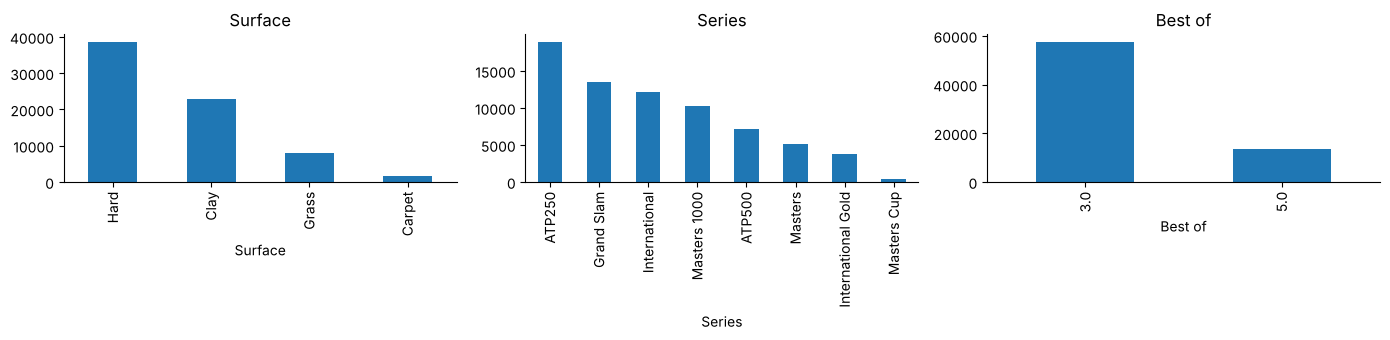

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column in zip(axes, ["Surface", "Series", "Best of"]):
    matches[column].value_counts().plot(kind="bar", ax=ax)
    ax.set_title(column)
plt.tight_layout()

### Bookmaker probabilities

The files have decimal odds from several bookmakers (which ones changes
over the years). A bookmaker's win probability is 1 / odds; the two players'
probabilities add up to a bit more than 1 (the bookmaker's margin), so they
are scaled to add up to 1. Where several bookmakers have odds, their
probabilities are averaged.

In [4]:
books = sorted({c[:-1] for c in matches.columns
                if c.endswith("W") and f"{c[:-1]}L" in matches.columns
                and c not in ("W", "Winner")
                and c[:-1] not in ("", "Max")})
book_probs = []
for book in books:
    odds_w = pd.to_numeric(matches[f"{book}W"], errors="coerce")
    odds_l = pd.to_numeric(matches[f"{book}L"], errors="coerce")
    valid = (odds_w > 1) & (odds_l > 1)
    p = (1 / odds_w) / (1 / odds_w + 1 / odds_l)
    book_probs.append(p.where(valid))
matches["book_p"] = pd.concat(book_probs, axis=1).mean(axis=1)
print("Bookmakers:", ", ".join(books))
print(f"Matches with odds: {matches['book_p'].notna().mean():.1%}")

Bookmakers: Avg, B&W, B365, BFE, CB, EX, GB, IW, LB, PS, SB, SJ, UB
Matches with odds: 94.6%


## 2. The Elo model

For two players with ratings $R_A$ and $R_B$, the chance that A wins is

$$P(A) = \frac{1}{1 + 10^{(R_B - R_A)/400}}$$

so a 100-point gap is about a 64% favourite and 200 points about 76%. After
the match each rating moves by $K \times (\text{result} - P)$: the winner
gains what the loser loses, and a shock win moves the ratings more.

The extras, each switched on by a setting:

- **K that shrinks with experience**: $K = a / (n + 5)^c$ where $n$ is
  the number of matches the player has had rated. New players' ratings move
  fast and settle down as they play more.
- **Surface ratings**: every player also has a hard, clay, grass and carpet
  rating, updated only on that surface. The prediction uses a mix:
  $(1 - w) \times$ overall $+ \; w \times$ surface.
- **Margin of victory**: K is scaled by how dominant the win was, using the
  winner's share of games: $1 + \beta \times (\text{share} - 0.58)$, where
  0.58 is a typical winner's share.
- **Best of 5**: the better player is more likely to win over 5 sets. The
  best-of-3 probability is turned into a chance of winning each set, and
  that into a best-of-5 probability.
- **Retirements** move the ratings fully, or not at all.
- **Starting ratings from the ranking**: by default a new player starts at
  1500, the average. But a new player ranked 40th should start much higher
  than one ranked 400th. With this switched on, a new player starts at the
  **average rating of the $n$ established players closest to them in the
  rankings** (players with 10+ rated matches who have played in the last
  year, closeness measured on a log scale). Their surface ratings still
  start at 1500 (starting those from the overall rating made predictions
  slightly worse).

Without a ranking or any neighbours, a new player starts at 1500.

In [5]:
def to_best_of_5(p):
    """Best-of-3 win probability -> best-of-5, via the chance of winning a
    set (assuming each set is independent)."""
    lo, hi = 0.0, 1.0  # solve p = s^2 (3 - 2s) for s by bisection
    for _ in range(40):
        s = (lo + hi) / 2
        if s * s * (3 - 2 * s) < p:
            lo = s
        else:
            hi = s
    return s ** 3 * (10 - 15 * s + 6 * s * s)


def expected(r_a, r_b):
    return 1 / (1 + 10 ** ((r_b - r_a) / 400))


DEFAULTS = dict(k_scale=250, k_power=0.4, surface_weight=0.0,
                margin=0.0, best_of_5=False, use_retirements=True,
                rank_start=0)
NEIGHBOUR_MIN_MATCHES = 10  # established players only
NEIGHBOUR_MAX_DAYS = 365  # who have played in the last year


def starting_rating(rank, today, latest_rank, overall, played, n):
    """A new player's starting rating: the average rating of the n
    established players whose latest ranking is closest to theirs.

    Closeness is measured on a log scale, so ranks 100 and 110 count as
    close as 10 and 11. Falls back to 1500 without a ranking or neighbours.
    """
    if not n or not rank > 0:
        return 1500.0
    log_rank = math.log(rank)
    nearby = sorted(
        (abs(math.log(r) - log_rank), overall[p])
        for p, (r, day) in latest_rank.items()
        if played.get(p, 0) >= NEIGHBOUR_MIN_MATCHES
        and today - day <= NEIGHBOUR_MAX_DAYS)[:n]
    if not nearby:
        return 1500.0
    return sum(rating for _, rating in nearby) / len(nearby)


def run_elo(matches, return_ratings=False, **settings):
    """Win probability of the actual winner before every match.

    Returns an array aligned with matches. The ratings are updated after
    each match, so every prediction uses only earlier matches. With
    return_ratings, also returns everyone's final overall rating, number of
    rated matches and date of their last match.
    """
    s = {**DEFAULTS, **settings}
    overall, surface = {}, {}  # player or (player, surface) -> rating
    played, surface_played, last_seen = {}, {}, {}
    latest_rank = {}  # player -> (ranking at their latest match, day)
    start = {}  # player -> (starting rating, ranking, date) at debut
    probs = np.empty(len(matches))
    columns = zip(matches["Winner"], matches["Loser"], matches["Surface"],
                  matches["Best of"], matches["retired"],
                  matches["Wgames"], matches["Lgames"], matches["Date"],
                  matches["WRank"], matches["LRank"])
    for i, (w, l, surf, best_of, retired, wg, lg, day, w_rank,
            l_rank) in enumerate(columns):
        last_seen[w] = last_seen[l] = day
        today = day.toordinal()
        for player, rank in ((w, w_rank), (l, l_rank)):
            if player not in overall:
                overall[player] = starting_rating(
                    rank, today, latest_rank, overall, played,
                    s["rank_start"])
                start[player] = (overall[player], rank, day)
        rw, rl = overall[w], overall[l]
        sw = surface.get((w, surf), 1500.0)
        sl = surface.get((l, surf), 1500.0)
        weight = s["surface_weight"]
        p = expected((1 - weight) * rw + weight * sw,
                     (1 - weight) * rl + weight * sl)
        p_overall, p_surface = expected(rw, rl), expected(sw, sl)
        if s["best_of_5"] and best_of == 5:
            p = to_best_of_5(p)
            p_overall = to_best_of_5(p_overall)
            p_surface = to_best_of_5(p_surface)
        probs[i] = p

        if retired and not s["use_retirements"]:
            continue
        boost = 1.0
        if s["margin"] and not retired and wg + lg > 0:
            boost = max(0.0, 1 + s["margin"] * (wg / (wg + lg) - 0.58))

        def k(n):
            return s["k_scale"] / (n + 5) ** s["k_power"] * boost

        nw, nl = played.get(w, 0), played.get(l, 0)
        overall[w] = rw + k(nw) * (1 - p_overall)
        overall[l] = rl - k(nl) * (1 - p_overall)
        played[w], played[l] = nw + 1, nl + 1
        nsw = surface_played.get((w, surf), 0)
        nsl = surface_played.get((l, surf), 0)
        surface[(w, surf)] = sw + k(nsw) * (1 - p_surface)
        surface[(l, surf)] = sl - k(nsl) * (1 - p_surface)
        surface_played[(w, surf)] = nsw + 1
        surface_played[(l, surf)] = nsl + 1
        for player, rank in ((w, w_rank), (l, l_rank)):
            if rank > 0:
                latest_rank[player] = (rank, today)
    if return_ratings:
        table = pd.DataFrame({"rating": overall, "matches": played,
                              "last_match": last_seen})
        debut = pd.DataFrame.from_dict(start, orient="index",
                                       columns=["start_rating", "debut_rank",
                                                "debut"])
        return probs, table.join(debut)
    return probs

### How predictions are scored

The data lists the winner first, so the prediction for a match is the
probability given to the player who actually won, $p$. That doesn't leak
the result: the model gives the same numbers whichever player is listed
first.

- **Accuracy**: the favourite won ($p > 0.5$).
- **Log loss**: $-\log p$, averaged. It punishes confident wrong
  predictions heavily; lower is better. A coin flip scores 0.693.
- **Brier score**: $(1 - p)^2$, averaged; lower is better. A coin flip
  scores 0.25.

In [6]:
def scores(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return {"accuracy": np.mean(p > 0.5), "log_loss": -np.mean(np.log(p)),
            "brier": np.mean((1 - p) ** 2), "matches": len(p)}

### Rolling evaluation: tuning on recent years

Tennis changes over time: the late-2000s/2010s Big Four era was unusually
predictable, and results have been more open since about 2017. Settings
chosen on one era can be wrong for the next (too slow to pick up a fast
riser, or too confident). So the model is re-tuned every year:

- **Test year Y** is predicted with settings chosen on the **3 years before
  it** (Y-3 to Y-1), as you would in practice at the start of each season.
- The first 5 years (2000-2004) are **warm-up** only, so the first test year
  is 2008. Every test year from then on is scored, giving about 46,000 test
  matches.

The ratings themselves always run over the whole history; only the
settings change from year to year, and each year's predictions use only
matches played before them.

In [7]:
WARMUP_YEARS = 5
VALIDATION_YEARS = 3
years = sorted(matches["Year"].unique())
test_years = years[WARMUP_YEARS + VALIDATION_YEARS:]
match_year = matches["Year"].to_numpy()
is_test = np.isin(match_year, test_years)
print(f"Warm-up {years[0]}-{years[WARMUP_YEARS - 1]}; test years "
      f"{test_years[0]}-{test_years[-1]} ({is_test.sum():,} matches), "
      f"each tuned on the {VALIDATION_YEARS} years before it")

Warm-up 2000-2004; test years 2008-2026 (48,233 matches), each tuned on the 3 years before it


## 3. Tuning, one step at a time

Each step adds one feature and tries a few settings for it, keeping the
others as already chosen. Settings are compared by **log loss on the
validation years**, which uses every match's probability, not just right or
wrong, so it is a steadier guide than accuracy. Each grid includes the
"off" setting, so a feature is only used if it improves on the step before.

Every distinct setting is run once and cached, since the same settings come
up for many test years.

In [8]:
STEPS = [
    ("Basic Elo", {"k_scale": [25, 35, 50, 75, 100, 150, 250],
                   "k_power": [0.0, 0.1, 0.2, 0.4]}),
    ("+ surface ratings", {"surface_weight": [0.0, 0.25, 0.5, 0.75]}),
    ("+ margin of victory", {"margin": [0.0, 2.0, 4.0, 8.0]}),
    ("+ best-of-5 adjustment", {"best_of_5": [False, True]}),
    ("+ retirements choice", {"use_retirements": [True, False]}),
    ("+ ranking-based start", {"rank_start": [0, 5, 10, 20]}),
]
cache = {}


def elo(settings):
    key = tuple(sorted(settings.items()))
    if key not in cache:
        cache[key] = run_elo(matches, **settings)
    return cache[key]


def tune(base, grid, mask):
    """Best settings on top of base, by log loss on the matches in mask."""
    best, best_loss = None, None
    keys = list(grid)
    for values in np.array(np.meshgrid(*grid.values()),
                           dtype=object).T.reshape(-1, len(keys)):
        settings = {**base, **dict(zip(keys, values))}
        loss = scores(elo(settings)[mask])["log_loss"]
        if best_loss is None or loss < best_loss:
            best, best_loss = settings, loss
    return best


chosen = {}  # test year -> {step name: settings}
for year in test_years:
    mask = (match_year >= year - VALIDATION_YEARS) & (match_year < year)
    settings, chosen[year] = dict(DEFAULTS), {}
    for name, grid in STEPS:
        settings = tune(settings, grid, mask)
        chosen[year][name] = settings
print(f"{len(cache)} distinct settings run")
final_settings = pd.DataFrame({y: c[STEPS[-1][0]]
                               for y, c in chosen.items()}).T
print("Final settings chosen for each test year:")
final_settings

111 distinct settings run
Final settings chosen for each test year:


,k_scale,k_power,surface_weight,margin,best_of_5,use_retirements,rank_start
2008,75,0.2,0.5,4.0,True,True,20
2009,75,0.2,0.5,2.0,True,True,10
2010,25,0.0,0.25,2.0,True,True,0
2011,25,0.0,0.25,2.0,True,True,0
2012,35,0.1,0.25,2.0,True,True,0
2013,35,0.1,0.5,4.0,True,True,0
2014,35,0.1,0.5,4.0,True,True,5
2015,35,0.1,0.25,2.0,True,True,0
2016,35,0.1,0.25,2.0,True,True,20
2017,150,0.4,0.25,2.0,True,True,5


### What the ranking-based start does

Starting ratings that some well-known players would get on their tour-level
debut, with each player's 10 nearest established neighbours in the rankings,
next to the 1500 everyone gets otherwise. Then a check of how newcomers
actually do: in matches between a newcomer (fewer than 10 tour-level
matches) and an established player, how often the newcomer was expected to
win, and how often they did.

In [9]:
example = {**chosen[test_years[-1]][STEPS[-1][0]], "rank_start": 10}
p_rank, debuts = run_elo(matches, return_ratings=True, **example)
famous = ["Nadal R.", "Djokovic N.", "Murray A.", "Del Potro J.M.",
          "Zverev A.", "Medvedev D.", "Sinner J.", "Alcaraz C.",
          "Fonseca J.", "Jodar R."]
print("Starting ratings with the 10 nearest-ranked established players:")
print(debuts.loc[[f for f in famous if f in debuts.index],
                 ["debut", "debut_rank", "start_rating"]]
      .round({"start_rating": 0}).to_string(), "\n")

p_flat = run_elo(matches, **{**example, "rank_start": 0})
count = {}
newcomer_w, newcomer_l = [], []
for w, l in zip(matches["Winner"], matches["Loser"]):
    nw, nl = count.get(w, 0), count.get(l, 0)
    newcomer_w.append(nw < 10 <= nl)
    newcomer_l.append(nl < 10 <= nw)
    count[w], count[l] = nw + 1, nl + 1
newcomer_w = np.array(newcomer_w) & is_test
newcomer_l = np.array(newcomer_l) & is_test
won = np.r_[np.ones(newcomer_w.sum()), np.zeros(newcomer_l.sum())]
print(f"Newcomer v established player, test years ({len(won):,} matches):")
print(f"  newcomer actually won:        {won.mean():.1%}")
for label, p in [("start at 1500", p_flat),
                 ("start from the ranking", p_rank)]:
    expected_win = np.r_[p[newcomer_w], 1 - p[newcomer_l]]
    print(f"  expected to win, {label + ':':24}{expected_win.mean():.1%}")

Starting ratings with the 10 nearest-ranked established players:
                    debut  debut_rank  start_rating
Nadal R.       2003-04-15       109.0        1490.0
Djokovic N.    2004-07-20       368.0        1469.0
Murray A.      2005-04-19       397.0        1458.0
Del Potro J.M. 2006-01-30       159.0        1464.0
Zverev A.      2013-07-15       798.0        1463.0
Medvedev D.    2016-05-16       244.0        1508.0
Sinner J.      2019-04-24       314.0        1462.0
Alcaraz C.     2020-02-18       406.0        1482.0
Fonseca J.     2023-02-20       827.0        1447.0
Jodar R.       2026-01-20       150.0        1486.0 



Newcomer v established player, test years (5,245 matches):
  newcomer actually won:        29.2%
  expected to win, start at 1500:          34.7%
  expected to win, start from the ranking: 34.6%


The ranking-based start works as intended, but it makes almost no
difference to the predictions: the tuning switches it on in 7 of the 19
test years, and the overall test results are identical to 4 decimal
places. The
examples above show why:

- **Players reach the tour ranked about 150-800**, even future champions,
  and established players at those rankings are rated about 1450-1500. So
  the ranking-based start is close to 1500 for nearly everyone. (Elo only
  depends on rating differences, so starting everyone at the same lower
  number would change nothing.)
- **Newcomers are weaker than either start assumes**: they won 29% of
  matches against established players, but were expected to win about
  35% either way. Much of a newcomer's ranking comes from lower-level
  events. Subtracting a "newcomer discount" from the start was tried and
  made predictions worse, because the extra points then flow to the
  established players they play.

A start that really helped would need information the tour-level results
don't have, such as Challenger results.

## 4. Results on the test years

Each step scored on all the test years together, each year using the
settings chosen for it. Alongside:

- **Higher ranking**: the higher-ranked player wins. It gives no
  probability, so only its accuracy is shown. An unranked player counts as
  ranked below everyone.
- **Bookmakers**: the averaged bookmaker probability, on the test matches
  that have odds.

In [10]:
def predictions(step):
    """Each match's prediction from the settings chosen for its year
    (NaN outside the test years)."""
    p = np.full(len(matches), np.nan)
    for year in test_years:
        rows = match_year == year
        p[rows] = elo(chosen[year][step])[rows]
    return p


results = {}
for name, _ in STEPS:
    matches[f"p_{name}"] = predictions(name)
    results[name] = scores(matches.loc[is_test, f"p_{name}"])
matches["elo_p"] = matches[f"p_{STEPS[-1][0]}"]

tested = matches[is_test]
# An unranked player counts as ranked below everyone.
ranked = (tested["WRank"].fillna(10_000) < tested["LRank"].fillna(10_000))
results["Higher ranking"] = {"accuracy": ranked.mean(),
                             "matches": len(tested)}
with_odds = tested["book_p"].notna()
results["Bookmakers (matches with odds)"] = scores(tested.loc[with_odds,
                                                               "book_p"])
results["Final Elo (same matches)"] = scores(tested.loc[with_odds, "elo_p"])
table = pd.DataFrame(results).T
table["accuracy"] = (table["accuracy"] * 100).round(1)
print(f"Test years {test_years[0]}-{test_years[-1]} (accuracy in %):")
table.round(4)

Test years 2008-2026 (accuracy in %):


,accuracy,log_loss,brier,matches
Basic Elo,66.2,0.6089,0.2111,48233.0
+ surface ratings,66.3,0.6057,0.2097,48233.0
+ margin of victory,66.5,0.6053,0.2094,48233.0
+ best-of-5 adjustment,66.6,0.6038,0.2089,48233.0
+ retirements choice,66.6,0.6038,0.2089,48233.0
+ ranking-based start,66.6,0.6038,0.2089,48233.0
Higher ranking,65.3,NaN,NaN,48233.0
Bookmakers (matches with odds),69.5,0.5739,0.1962,48147.0
Final Elo (same matches),66.6,0.6038,0.2089,48147.0


### Saving the predictions

Every test-year match with its Elo probability (the chance the actual winner
was given before the match, using the settings chosen for that year) is
saved to `data/elo_predictions.csv` for other notebooks to use, e.g.
`nmf.ipynb`.

In [11]:
os.makedirs("data", exist_ok=True)
saved = matches.loc[is_test, ["Date", "Year", "Tournament", "Series",
                              "Surface", "Round", "Best of", "Winner",
                              "Loser", "WRank", "LRank", "retired",
                              "elo_p"]]
saved.to_csv(os.path.join("data", "elo_predictions.csv"), index=False)
print(f"Saved {len(saved):,} matches to data/elo_predictions.csv")

Saved 48,233 matches to data/elo_predictions.csv


### Year by year

How the final Elo, the rankings and the bookmakers do each year. The dip
from about 2017 shows up in all three: results became harder to predict
after the Big Four era.

Year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
elo,68.1,68.7,68.7,68.4,70.1,68.0,68.6,68.4,69.0,66.8,64.7,64.5,64.7,62.3,64.9,63.8,64.9,64.1,64.6
ranking,66.8,67.6,66.3,67.3,67.6,65.7,67.7,67.9,67.1,65.1,63.4,61.4,63.4,62.7,64.1,63.9,63.7,64.4,64.0
bookmakers,70.726172,70.37449,70.93856,72.305953,72.070688,69.90144,70.718232,71.134021,71.116226,68.02903,68.259386,67.302452,69.809826,68.016194,67.813456,67.524236,68.391867,67.309175,67.974414


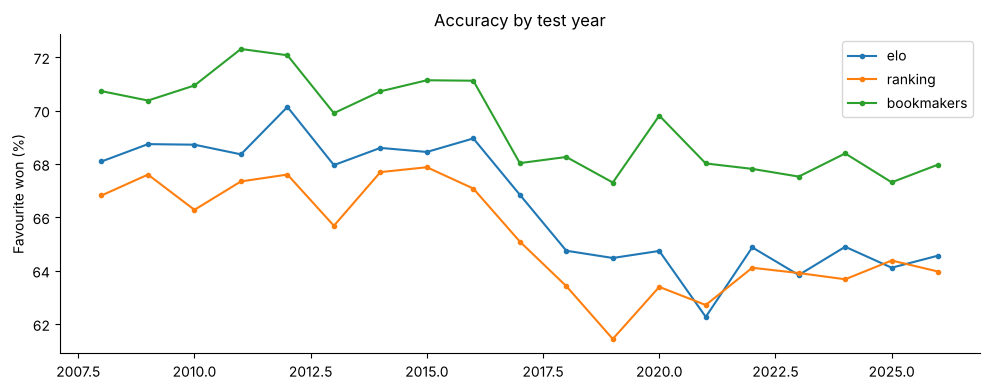

In [12]:
by_year = tested.assign(
    elo=tested["elo_p"] > 0.5,
    ranking=ranked,
    bookmakers=(tested["book_p"] > 0.5).where(with_odds)
).groupby("Year")[["elo", "ranking", "bookmakers"]].mean() * 100
ax = by_year.plot(marker=".", title="Accuracy by test year")
ax.set_ylabel("Favourite won (%)")
ax.set_xlabel("")
plt.tight_layout()
by_year.round(1).T

### Calibration

A well-calibrated model's 70% favourites should win about 70% of the time.
Each point below groups test matches by the predicted chance of the
favourite.

,predicted,won,matches
elo_p,,,
"(0.5, 0.55]",0.525,0.520,7830
"(0.55, 0.6]",0.575,0.567,7463
"(0.6, 0.65]",0.625,0.600,6857
"(0.65, 0.7]",0.675,0.664,6261
"(0.7, 0.75]",0.724,0.697,5301
"(0.75, 0.8]",0.774,0.751,4591
"(0.8, 0.85]",0.824,0.785,3755
"(0.85, 0.9]",0.874,0.847,2821
"(0.9, 0.95]",0.924,0.891,2054


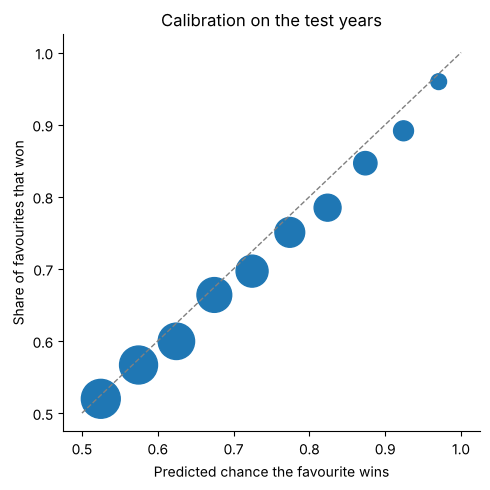

In [13]:
fav_p = np.maximum(tested["elo_p"], 1 - tested["elo_p"])
fav_won = tested["elo_p"] > 0.5
bins = pd.cut(fav_p, np.arange(0.5, 1.0001, 0.05))
calibration = pd.DataFrame({"predicted": fav_p, "won": fav_won}) \
    .groupby(bins, observed=True).agg(predicted=("predicted", "mean"),
                                      won=("won", "mean"),
                                      matches=("won", "size"))
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0.5, 1], [0.5, 1], color="grey", linestyle="--", linewidth=1)
ax.scatter(calibration["predicted"], calibration["won"],
           s=calibration["matches"] / 10)
ax.set_xlabel("Predicted chance the favourite wins")
ax.set_ylabel("Share of favourites that won")
ax.set_title("Calibration on the test years")
plt.tight_layout()
calibration.round(3)

## 5. Current ratings\n\nThe top of the overall ratings after the last match in the data, with the settings chosen for the latest year: players with 50+ rated matches who played in that year.

In [14]:
latest = chosen[test_years[-1]][STEPS[-1][0]]
_, ratings = run_elo(matches, return_ratings=True, **latest)
active = ((ratings["matches"] >= 50)
          & (ratings["last_match"].dt.year == years[-1]))
print(f"After {matches['Date'].max():%d %b %Y}:")
ratings.loc[active, ["rating", "matches", "last_match"]] \
    .sort_values("rating", ascending=False).head(15).round({"rating": 0})

After 18 Oct 2026:


,rating,matches,last_match
Sinner J.,2192.0,434,2026-07-12
Alcaraz C.,2086.0,361,2026-10-12
Zverev A.,1946.0,760,2026-10-17
Djokovic N.,1929.0,1334,2026-10-09
Fils A.,1853.0,173,2026-10-12
Shelton B.,1840.0,238,2026-10-11
Medvedev D.,1829.0,624,2026-10-17
Davidovich Fokina A.,1820.0,340,2026-10-18
Tiafoe F.,1807.0,484,2026-10-11
Fritz T.,1801.0,555,2026-10-12


## Summary

Over the test years 2008-2026 (48,233 matches, each year tuned on the 3
before it):

- **The final Elo picks the winner 66.6% of the time** (log loss 0.604),
  against 65.3% for the higher-ranked player and 69.5% for the bookmakers
  (log loss 0.574).
- **Every step helps a little.** Surface ratings and the best-of-5
  adjustment help most; margin of victory adds a little; leaving
  retirements out never helped, so they always count. Starting new players
  from the ratings of players ranked around them made no difference.
- **Tennis got harder to predict from about 2017.** All three methods drop
  by 3-5 points from the Big Four era. Elo's lead over the rankings shrank
  from 1-2 points to almost nothing since 2021, while the bookmakers' lead
  over Elo grew from about 2 points to 3-4.
- **Re-tuning each year barely changes this**, so the drop is about the
  era, not stale settings. The chosen K is mostly small (slow-moving
  ratings), with a small margin-of-victory effect.
- **The Elo is slightly overconfident**: its 80-85% favourites win 78.5%
  of the time.

Likely reasons the bookmakers (and lately the rankings) do better: they
also see Challenger and ITF results, so rising players such as new
teenagers are rated properly, where this Elo starts everyone at 1500 and
only sees tour-level matches; and bookmakers know about injuries and form.

Things to try next:

- **Confidence scaling**: shrink the rating difference a little when
  predicting, tuned on the validation years, to fix the overconfidence.
- **Challenger results**: starting new players from the ratings of
  players ranked around them was tried and made no difference (see section
  3); feeding in Challenger matches would give newcomers real ratings.
- **Inactivity**: pull a player's rating back towards average after a long
  injury break.
- **Tournament level**: a larger K for Grand Slams and Masters.
- **Charting data**: serve and return ratings from the Match Charting
  Project, for the matches it covers.